In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import LinearSegmentedColormap
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# ---------------- style ----------------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 11,
    "savefig.dpi": 300,
})
RED, GREEN = "#C0392B", "#1E8449"
SHOW_ANGLE = True  # arc + theta between the two kernel directions


In [6]:
# ---- map and its Jacobian ----
def f(x, y, z):
    return np.array([x**2, y, -x**2 - y**2])

def jac_f(x, y, z):
    # rows = output components, cols = d/dx, d/dy, d/dz
    return np.array([[2 * x, 0.0, 0.0],
                     [0.0, 1.0, 0.0],
                     [-2 * x, -2 * y, 0.0]])

def null_space(A, tol=1e-10):
    _, s, Vt = np.linalg.svd(A)
    return Vt[(s > tol).sum():].T  # columns span ker A

In [7]:
# ---- input plane M = {z = 0}, point p on the fold x = 0 ----
p = np.array([0.0, 0.3, 0.0])
e1, e2 = np.array([1.0, 0, 0]), np.array([0, 1.0, 0])   # basis of T_pM
J = jac_f(*p)
K = null_space(J)                       # ker df_p (here span{e_x, e_z})
# ker df_p ∩ T_pM: null space of J restricted to T_pM
B = np.stack([e1, e2], 1)
kt = B @ null_space(J @ B)              # columns in R^3
v_ker = kt[:, 0] / np.linalg.norm(kt[:, 0])
v_ok = e2                               # a tangent direction NOT in the kernel
print("ker df_p:\n", K.round(3), "\nker ∩ T_pM:", v_ker.round(3))

ker df_p:
 [[0. 1.]
 [0. 0.]
 [1. 0.]] 
ker ∩ T_pM: [1. 0. 0.]


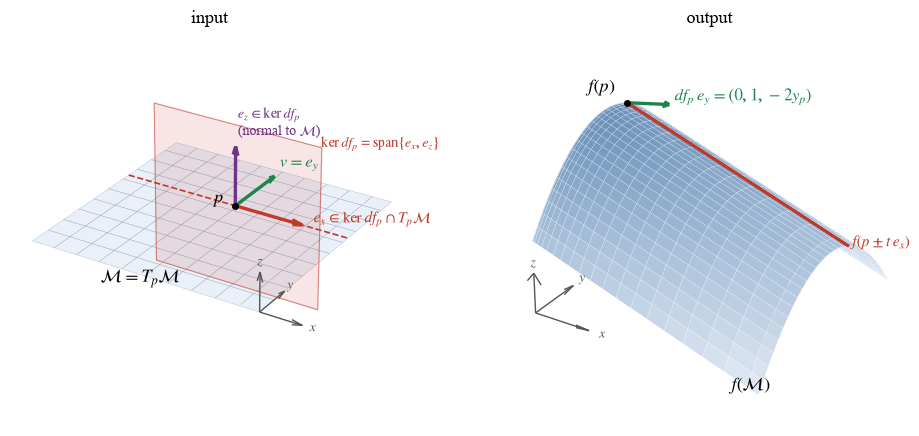

In [8]:
g = np.linspace(-1, 1, 60)
X, Y = np.meshgrid(g, g)
Z = np.zeros_like(X)
FX, FY, FZ = f(X, Y, Z)

PURPLE, GREY = "#6C3483", "#555555"

def triad(a, o, L=0.35, scale=(1, 1, 1)):
    """Coordinate axes x, y, z drawn from corner point o; scale undoes unequal axis ranges."""
    for d, lab in zip(np.eye(3) * np.asarray(scale, float), "xyz"):
        a.quiver(*o, *(L * d), color=GREY, arrow_length_ratio=0.25, linewidth=1.0, zorder=11)
        a.text(*(o + 1.25 * L * d), f"${lab}$", color=GREY, fontsize=10,
               ha="center", va="center", zorder=14)

cmap = LinearSegmentedColormap.from_list("m", ["#DCE6F2", "#9BB7D4", "#4F7CAC"])
fig = plt.figure(figsize=(10, 4.2))

# ================= left: input plane =================
ax = fig.add_subplot(121, projection="3d", computed_zorder=False)
ax.plot_surface(X, Y, Z, color="#DCE6F2", alpha=0.6, linewidth=0.2,
                edgecolor=(0.3, 0.4, 0.6, 0.3), rcount=11, ccount=11, shade=False, zorder=1)
# ker df_p as a translucent plane through p
s = 0.75
kc = [p + a * s * K[:, 0] + b * s * K[:, 1] for a, b in [(-1, -1), (1, -1), (1, 1), (-1, 1)]]
ax.add_collection3d(Poly3DCollection([kc], facecolor=(0.75, 0.22, 0.17, 0.12),
                                     edgecolor=(0.75, 0.22, 0.17, 0.6), linewidth=0.8, zorder=2))
# intersection line ker ∩ T_pM
t = np.linspace(-1, 1, 2)
ax.plot(*(p[:, None] + v_ker[:, None] * t), color=RED, lw=1.2, ls="--", zorder=8)
kw = dict(arrow_length_ratio=0.15, linewidth=2.4, zorder=12)
ax.quiver(*p, *(0.6 * v_ker), color=RED, **kw)
ax.quiver(*p, *(0.6 * v_ok), color=GREEN, **kw)
# e_z: always in ker df_p (f ignores z), but normal to M so not a tangent direction
ez = np.array([0.0, 0, 1.0])
ax.quiver(*p, *(0.55 * ez), color=PURPLE, **kw)
ax.text(*(p + 0.62 * ez + [0.02, 0, 0]), r"$e_z \in \ker df_p$" + "\n" + r"(normal to $\mathcal{M}$)",
        color=PURPLE, fontsize=10, ha="left", va="bottom", zorder=14)
ax.scatter(*p, color="k", s=16, depthshade=False, zorder=13)
ax.text(*(p + np.array([-0.12, -0.12, 0.05])), r"$p$", fontsize=13, zorder=14)
ax.text(*(p + 0.7 * v_ker + [0, 0, 0.05]), r"$e_x \in \ker df_p \cap T_p\mathcal{M}$", color=RED,
        fontsize=11, zorder=14)
ax.text(*(p + 0.68 * v_ok + [0, 0, 0.05]), r"$v = e_y$", color=GREEN, fontsize=12, zorder=14)
ax.text(*(p + s * K[:, 0] + s * K[:, 1]), r"$\ker df_p = \mathrm{span}\{e_x, e_z\}$", color=RED, fontsize=10, zorder=14)
ax.text(-0.2, -1.25, 0, r"$\mathcal{M}=T_p\mathcal{M}$", fontsize=13, ha="left", zorder=14)
triad(ax, np.array([1.0, -1.0, 0.0]))
ax.set_title("input", pad=-10)

# ================= right: image surface =================
bx = fig.add_subplot(122, projection="3d", computed_zorder=False)
xp = np.linspace(0, 1, 40)                       # f folds x and -x together
Xp, Yp = np.meshgrid(xp, g)
SX, SY, SZ = f(Xp, Yp, 0 * Xp)
bx.plot_surface(SX, SY, SZ, cmap=cmap, alpha=0.85, linewidth=0.15,
                edgecolor=(1, 1, 1, 0.25), rcount=30, ccount=30, shade=True, zorder=1)
q = f(*p)
# image of the kernel line: collapses to a fold curve, traced twice
tt = np.linspace(-1, 1, 100)
c = f(p[0] + tt, p[1] + 0 * tt, 0)
bx.plot(*c, color=RED, lw=2.0, zorder=10)
bx.quiver(*q, *(0.6 * J @ v_ok), color=GREEN, **kw)
bx.scatter(*q, color="k", s=16, depthshade=False, zorder=13)
bx.text(*(q + np.array([-0.15, -0.1, 0.08])), r"$f(p)$", fontsize=13, zorder=14)
bx.text(*(q + 0.68 * J @ v_ok + [0, 0, 0.05]), r"$df_p\,e_y = (0, 1, -2y_p)$", color=GREEN, fontsize=12, zorder=14)
bx.text(*(c[:, -1] + [0.02, 0, 0]), r"$f(p\pm t\,e_x)$", color=RED, fontsize=11, zorder=14)
bx.text(0.9, -1.05, -2.0, r"$f(\mathcal{M})$", fontsize=13, zorder=14)
triad(bx, np.array([0.0, -1.0, -1.9]), L=0.5, scale=(0.5, 1, 1))
bx.set_title("output", pad=-10)

for a in (ax, bx):
    a.view_init(elev=28, azim=-58)
    a.set_box_aspect((1, 1, 0.7))
    a.set_axis_off()
ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-0.75, 0.75)
bx.set_xlim(0, 1); bx.set_ylim(-1, 1); bx.set_zlim(-2, 0)
fig.subplots_adjust(left=0, right=1, bottom=0, top=0.95, wspace=0)
plt.savefig("plane_kernel_fold.pdf", bbox_inches="tight", pad_inches=0.02)
plt.savefig("plane_kernel_fold.png", bbox_inches="tight", pad_inches=0.02)

ker df_p: [1. 0. 0.]  sigma(J @ B) = [1.22  0.512]  -> ker ∩ T_pM = {0} | angle(ker, T_pM) = 38.7 deg


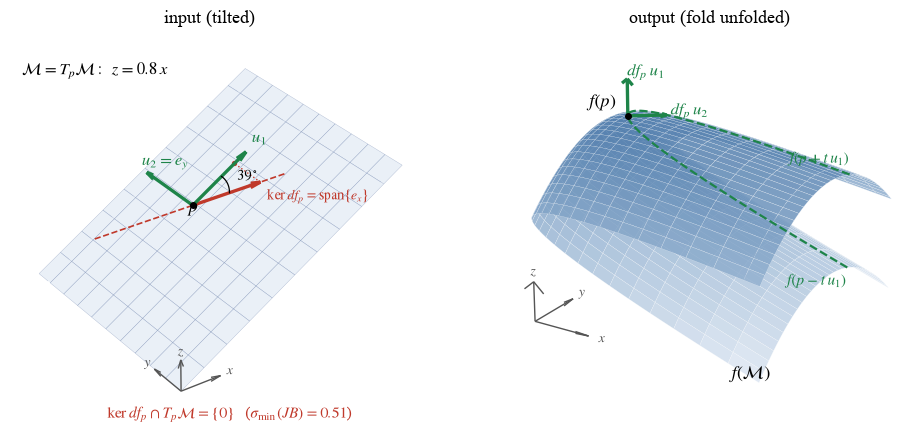

In [9]:
# ---- tilted input plane, z-dependent f: ker df_p ∩ T_pM = {0} ----
def f2(x, y, z):
    return np.array([x**2, y, -x**2 - y**2 + z])

def jac_f2(x, y, z):
    return np.array([[2 * x, 0.0, 0.0],
                     [0.0, 1.0, 0.0],
                     [-2 * x, -2 * y, 1.0]])

a_tilt = 0.8                                   # input plane M: z = a_tilt * x (tilt about the y-axis)
p2 = np.array([0.0, 0.3, 0.0])                 # still on the fold x = 0, where det J2 = 2x = 0
u1 = np.array([1.0, 0.0, a_tilt]); u1 /= np.linalg.norm(u1)
u2 = np.array([0.0, 1.0, 0.0])
B2 = np.stack([u1, u2], 1)                     # orthonormal basis of T_pM
J2 = jac_f2(*p2)
K2 = null_space(J2)                            # ker df_p = span{e_x}, 1-D
k2 = K2[:, 0] * np.sign(K2[0, 0])
sig = np.linalg.svd(J2 @ B2, compute_uv=False)
n2 = np.cross(u1, u2)
ang = np.degrees(np.arcsin(abs(k2 @ n2)))      # angle between kernel line and the plane
print("ker df_p:", k2.round(3), " sigma(J @ B) =", sig.round(3),
      f" -> ker ∩ T_pM = {{0}}" if sig.min() > 1e-8 else " -> nontrivial",
      f"| angle(ker, T_pM) = {ang:.1f} deg")

fig = plt.figure(figsize=(10, 4.2))

# ================= left: tilted input plane =================
ax = fig.add_subplot(121, projection="3d", computed_zorder=False)
U, V = np.meshgrid(g, g)                        # plane coordinates along (e_x-ish, e_y)
PX, PY, PZ = U, V, a_tilt * U
ax.plot_surface(PX, PY, PZ, color="#DCE6F2", alpha=0.6, linewidth=0.2,
                edgecolor=(0.3, 0.4, 0.6, 0.3), rcount=11, ccount=11, shade=False, zorder=1)
# kernel line through p: leaves the plane (only meets it at p)
tk = np.linspace(-0.9, 0.9, 2)
ax.plot(*(p2[:, None] + k2[:, None] * tk), color=RED, lw=1.2, ls="--", zorder=8)
ax.quiver(*p2, *(0.65 * k2), color=RED, **kw)
# drop the kernel arrow's tip onto the plane: the gap shows e_x leaves T_pM
tip = p2 + 0.65 * k2
foot = tip - ((tip - p2) @ n2) * n2
ax.plot(*np.stack([tip, foot], 1), color=RED, lw=1.0, ls=":", zorder=11)
ax.scatter(*foot, color=RED, s=8, depthshade=False, zorder=12)
ax.quiver(*p2, *(0.65 * u1), color=GREEN, **kw)
ax.quiver(*p2, *(0.65 * u2), color=GREEN, **kw)
ax.scatter(*p2, color="k", s=16, depthshade=False, zorder=13)
# angle arc between e_x and u1 (both in the xz-plane)
th = np.linspace(0, np.arctan(a_tilt), 30)
arc = p2[:, None] + 0.35 * np.stack([np.cos(th), 0 * th, np.sin(th)])
ax.plot(*arc, color="k", lw=0.9, zorder=12)
ax.text(*(p2 + 0.45 * np.array([np.cos(th[15]), 0, np.sin(th[15])])), rf"${ang:.0f}^\circ$",
        fontsize=10, ha="left", va="center", zorder=14)
ax.text(*(p2 + np.array([-0.12, -0.12, 0.05])), r"$p$", fontsize=13, zorder=14)
ax.text(*(p2 + 0.72 * k2 + [0, 0, -0.12]), r"$\ker df_p = \mathrm{span}\{e_x\}$", color=RED,
        fontsize=10, ha="left", va="top", zorder=14)
ax.text(*(p2 + 0.72 * u1 + [0, 0, 0.04]), r"$u_1$", color=GREEN, fontsize=12, zorder=14)
ax.text(*(p2 + 0.72 * u2 + [0, 0, 0.04]), r"$u_2 = e_y$", color=GREEN, fontsize=12, zorder=14)
ax.text2D(0.03, 0.88, r"$\mathcal{M}=T_p\mathcal{M}:\ z = %.1f\,x$" % a_tilt,
          transform=ax.transAxes, fontsize=12, ha="left", zorder=14)
ax.text2D(0.55, 0.02, r"$\ker df_p \cap T_p\mathcal{M} = \{0\}$" + f"   ($\\sigma_{{\\min}}(J B) = {sig.min():.2f}$)",
          transform=ax.transAxes, ha="center", fontsize=11, color=RED)
triad(ax, np.array([-1.0, -1.0, -0.8]))
ax.set_title("input (tilted)", pad=-10)

# ================= right: image surface (no fold) =================
bx = fig.add_subplot(122, projection="3d", computed_zorder=False)
SX, SY, SZ = f2(PX, PY, PZ)
bx.plot_surface(SX, SY, SZ, cmap=cmap, alpha=0.85, linewidth=0.15,
                edgecolor=(1, 1, 1, 0.25), rcount=30, ccount=30, shade=True, zorder=1)
q2 = f2(*p2)
# image of the in-plane line p + t u1: x and -x no longer coincide
c2 = f2(*(p2[:, None] + np.linspace(-1, 1, 100) * u1[:, None] * np.sqrt(1 + a_tilt**2)))
bx.plot(*c2, color=GREEN, lw=1.6, ls="--", zorder=10)
bx.quiver(*q2, *(0.65 * J2 @ u1 / np.linalg.norm(J2 @ u1)), color=GREEN, **kw)
bx.quiver(*q2, *(0.65 * J2 @ u2 / np.linalg.norm(J2 @ u2)), color=GREEN, **kw)
bx.scatter(*q2, color="k", s=16, depthshade=False, zorder=13)
bx.text(*(q2 + np.array([-0.15, -0.1, 0.1])), r"$f(p)$", fontsize=13, zorder=14)
bx.text(*(q2 + 0.7 * J2 @ u1 / np.linalg.norm(J2 @ u1)), r"$df_p\,u_1$", color=GREEN,
        fontsize=12, ha="left", zorder=14)
bx.text(*(q2 + 0.72 * J2 @ u2 / np.linalg.norm(J2 @ u2)), r"$df_p\,u_2$", color=GREEN,
        fontsize=12, ha="left", zorder=14)
bx.text(*(c2[:, -1] + [0, 0, 0.12]), r"$f(p+t\,u_1)$", color=GREEN, fontsize=11,
        ha="right", va="bottom", zorder=14)
bx.text(*(c2[:, 0] + [0, 0, -0.12]), r"$f(p-t\,u_1)$", color=GREEN, fontsize=11,
        ha="right", va="top", zorder=14)
bx.text(0.9, -1.05, SZ.min(), r"$f(\mathcal{M})$", fontsize=13, zorder=14)
triad(bx, np.array([0.0, -1.0, SZ.min()]), L=0.5, scale=(0.5, 1, 1.4))
bx.set_title("output (fold unfolded)", pad=-10)

ax.view_init(elev=30, azim=-125)                # look across the tilt so u1, u2 separate
bx.view_init(elev=22, azim=-58)
for a_ in (ax, bx):
    a_.set_box_aspect((1, 1, 0.7))
    a_.set_axis_off()
ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-0.9, 0.9)
bx.set_xlim(0, 1); bx.set_ylim(-1, 1); bx.set_zlim(SZ.min(), SZ.max())
fig.subplots_adjust(left=0, right=1, bottom=0, top=0.95, wspace=0)
plt.savefig("plane_kernel_tilted.pdf", bbox_inches="tight", pad_inches=0.02)
plt.savefig("plane_kernel_tilted.png", bbox_inches="tight", pad_inches=0.02)